# CUAD Data Exploration

## Goal

The goal of this notebook is to understand the structure of the CUAD dataset before preprocessing and chunking the contracts.

We will examine:
- the dataset structure
- number of contracts
- contract text
- clause categories and annotations
- document length
- class distribution
- possible data quality issues

This exploration will help us decide how to split and chunk the contracts for modeling.

In [2]:
import json
from pathlib import Path

data_path = Path("../data/CUADv1.json")

with open(data_path, "r", encoding="utf-8") as file:
    data = json.load(file)

print("Dataset loaded successfully!")
print("Top-level type:", type(data))

Dataset loaded successfully!
Top-level type: <class 'dict'>


In [3]:
print(data.keys())


dict_keys(['version', 'data'])


In [4]:
contracts = data["data"]

print("Number of contracts:", len(contracts))
print("Type of contracts:", type(contracts))


Number of contracts: 510
Type of contracts: <class 'list'>


In [5]:
print(contracts[0].keys())

dict_keys(['title', 'paragraphs'])


In [6]:
first_contract = contracts[0]

print("Title:", first_contract["title"])
print("Number of paragraphs:", len(first_contract["paragraphs"]))

Title: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of paragraphs: 1


In [7]:
first_paragraph = first_contract["paragraphs"][0]

print("Paragraph keys:", first_paragraph.keys())

Paragraph keys: dict_keys(['qas', 'context'])


In [8]:

qas = first_paragraph["qas"]

print("Number of QAs:", len(qas))
print("First QA keys:", qas[0].keys())

Number of QAs: 41
First QA keys: dict_keys(['answers', 'id', 'question', 'is_impossible'])


In [9]:
contract_text = first_contract["paragraphs"][0]["context"]

print(contract_text)

EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

                                    RECITALS

         A. The  Company's  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an "Energy  Saver"  which may be improved  or  otherwise  changed  from its present composition (the "Products").  The Company may engage in the business of selling other  products  or  other  devices  other  than  the  Products,  which  will be considered  Products if Distributor  exercises its options pursuant to Section 7 hereof.

         B. Representations.  As an inducement to the Company to enter into this Agreement,  the  Distributor  has  represented  that  it has or  will  have  the facil

In [10]:

print(json.dumps(contracts[0], indent=2)[:5000])

{
  "title": "LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT",
  "paragraphs": [
    {
      "qas": [
        {
          "answers": [
            {
              "text": "DISTRIBUTOR AGREEMENT",
              "answer_start": 44
            }
          ],
          "id": "LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name",
          "question": "Highlight the parts (if any) of this contract related to \"Document Name\" that should be reviewed by a lawyer. Details: The name of the contract",
          "is_impossible": false
        },
        {
          "answers": [
            {
              "text": "Distributor",
              "answer_start": 244
            },
            {
              "text": "Electric City Corp.",
              "answer_start": 148
            },
            {
              "text": "Electric City of Illinois L.L.C.",
              "answer_start": 49574
            },
            {
              "text": "Company",
              "answer_start

In [11]:
first_qa = qas[0]

print("Question:", first_qa["question"])
print("ID:", first_qa["id"])
print("Is impossible:", first_qa["is_impossible"])
print("Number of answers:", len(first_qa["answers"]))

Question: Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract
ID: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name
Is impossible: False
Number of answers: 1


In [12]:
print(first_qa["answers"])

[{'text': 'DISTRIBUTOR AGREEMENT', 'answer_start': 44}]


In [13]:
for i, qa in enumerate(qas):
    print(i, "-", qa["question"])

0 - Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract
1 - Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
2 - Highlight the parts (if any) of this contract related to "Agreement Date" that should be reviewed by a lawyer. Details: The date of the contract
3 - Highlight the parts (if any) of this contract related to "Effective Date" that should be reviewed by a lawyer. Details: The date when the contract is effective 
4 - Highlight the parts (if any) of this contract related to "Expiration Date" that should be reviewed by a lawyer. Details: On what date will the contract's initial term expire?
5 - Highlight the parts (if any) of this contract related to "Renewal Term" that should be reviewed by a lawyer. Details: What is the renewal term after the initial term expires? This includes a

In [14]:
qa_counts = []

for contract in contracts:
    paragraphs = contract["paragraphs"]

    total_qas = 0
    for paragraph in paragraphs:
        total_qas += len(paragraph["qas"])

    qa_counts.append(total_qas)

print("Number of contracts:", len(contracts))
print("Minimum QAs:", min(qa_counts))
print("Maximum QAs:", max(qa_counts))
print("Unique QA counts:", sorted(set(qa_counts)))

Number of contracts: 510
Minimum QAs: 41
Maximum QAs: 41
Unique QA counts: [41]


In [15]:
has_answer = 0
no_answer = 0

for contract in contracts:
    for paragraph in contract["paragraphs"]:
        for qa in paragraph["qas"]:
            if qa["is_impossible"]:
                no_answer += 1
            else:
                has_answer += 1

print("Has answer:", has_answer)
print("No answer:", no_answer)
print("Total:", has_answer + no_answer)

Has answer: 6702
No answer: 14208
Total: 20910


In [16]:
category_counts = {}

for contract in contracts:
    for paragraph in contract["paragraphs"]:
        for qa in paragraph["qas"]:

            category = qa["question"].split('"')[1]

            if category not in category_counts:
                category_counts[category] = 0

            if not qa["is_impossible"]:
                category_counts[category] += 1

for category, count in sorted(category_counts.items(),
                              key=lambda x: x[1],
                              reverse=True):
    print(category, ":", count)

Document Name : 510
Parties : 509
Agreement Date : 470
Governing Law : 437
Expiration Date : 413
Effective Date : 390
Anti-Assignment : 374
Cap On Liability : 275
License Grant : 255
Audit Rights : 214
Termination For Convenience : 183
Post-Termination Services : 182
Exclusivity : 180
Renewal Term : 176
Revenue/Profit Sharing : 166
Insurance : 166
Minimum Commitment : 165
Non-Transferable License : 138
Ip Ownership Assignment : 124
Change Of Control : 121
Non-Compete : 119
Notice Period To Terminate Renewal : 111
Uncapped Liability : 111
Covenant Not To Sue : 100
Rofr/Rofo/Rofn : 85
Volume Restriction : 82
Competitive Restriction Exception : 76
Warranty Duration : 75
Irrevocable Or Perpetual License : 70
Liquidated Damages : 61
No-Solicit Of Employees : 59
Affiliate License-Licensee : 59
Joint Ip Ownership : 46
Non-Disparagement : 38
No-Solicit Of Customers : 34
Third Party Beneficiary : 32
Most Favored Nation : 28
Affiliate License-Licensor : 23
Unlimited/All-You-Can-Eat-License : 17


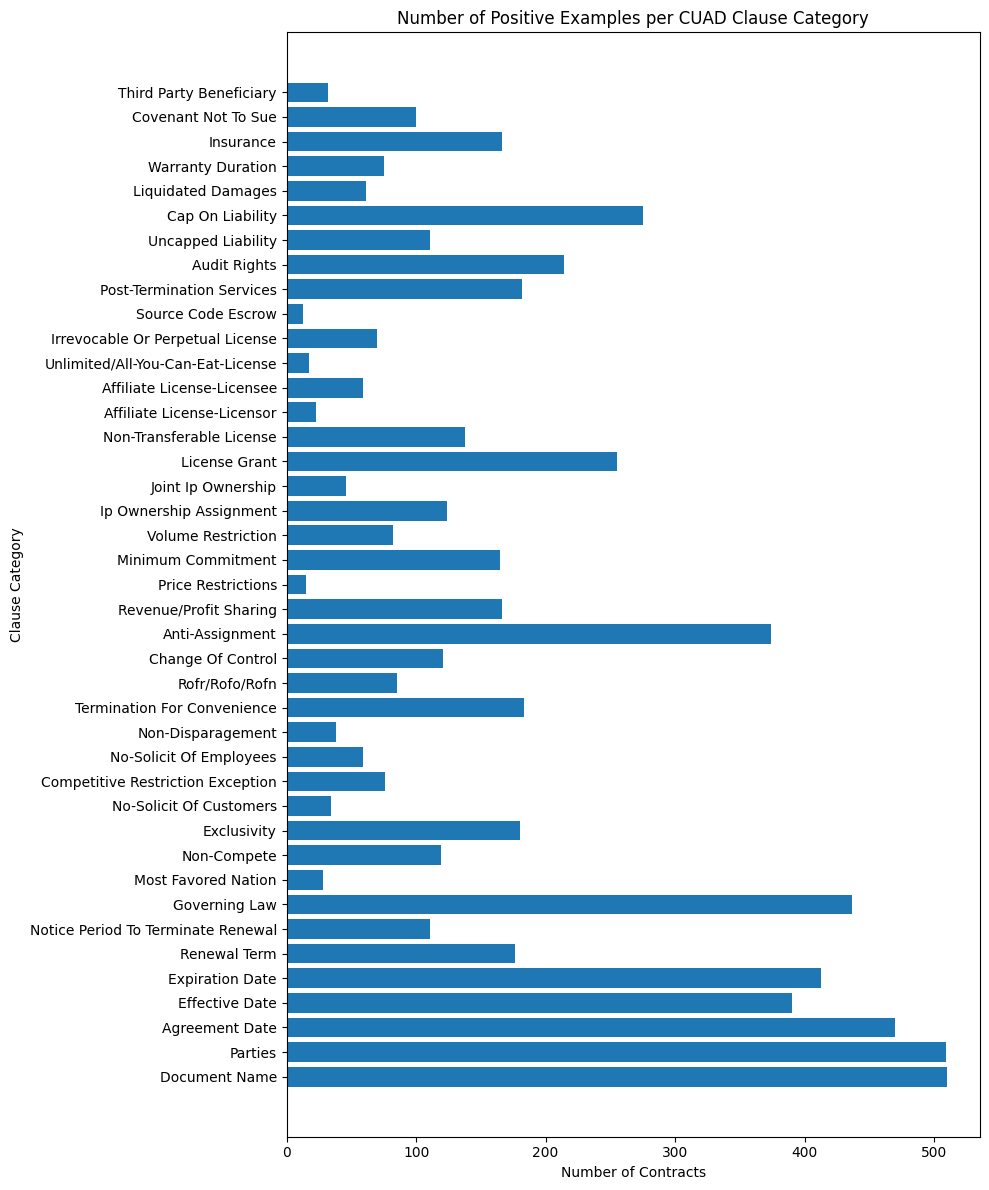

In [17]:
import matplotlib.pyplot as plt

categories = list(category_counts.keys())
counts = list(category_counts.values())

plt.figure(figsize=(10, 12))

plt.barh(categories, counts)

plt.xlabel("Number of Contracts")
plt.ylabel("Clause Category")
plt.title("Number of Positive Examples per CUAD Clause Category")

plt.tight_layout()
plt.show()

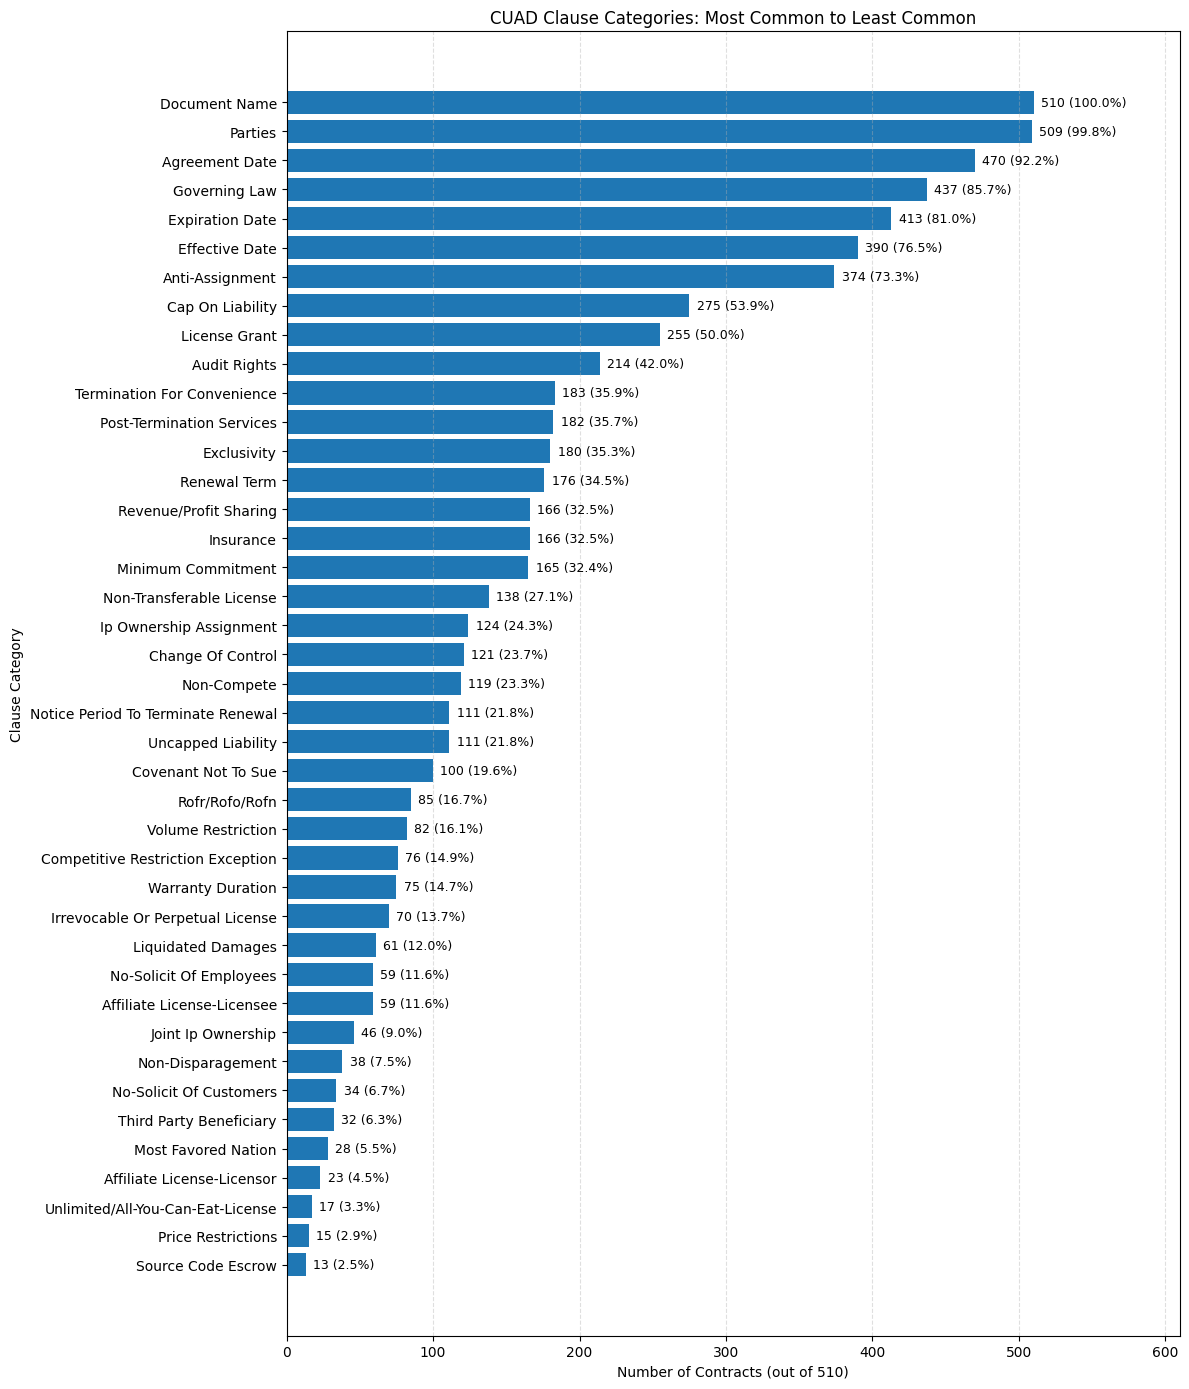

In [18]:
import matplotlib.pyplot as plt

# Sort categories from most common to least common
sorted_categories = sorted(
    category_counts.items(),
    key=lambda x: x[1],
    reverse=True
)

categories = [item[0] for item in sorted_categories]
counts = [item[1] for item in sorted_categories]

total_contracts = len(contracts)

# Make graph larger
plt.figure(figsize=(12, 14))

bars = plt.barh(categories, counts)

# Put most common category at the top
plt.gca().invert_yaxis()

# Add count and percentage beside each bar
for bar, count in zip(bars, counts):
    percentage = (count / total_contracts) * 100

    plt.text(
        count + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=9
    )

plt.xlabel("Number of Contracts (out of 510)")
plt.ylabel("Clause Category")
plt.title("CUAD Clause Categories: Most Common to Least Common")

# Makes the numbers easier to compare
plt.grid(axis="x", linestyle="--", alpha=0.4)

# Give room for numbers on the right
plt.xlim(0, max(counts) + 100)

plt.tight_layout()
plt.show()

## Conclusion so far from this Data Exploration

- The dataset contains **510 contracts**.
- Each contract has the same **41 clause categories** that are checked for possible matches.
- There are **20,910 total contract–clause checks** (510 × 41).
- Only **6,702** of these have a matching clause, while **14,208** have no matching clause.
- The clause categories are **not evenly distributed**. Some appear in almost every contract, while others are very rare.
- For example, **Document Name** appears in all 510 contracts, while **Source Code Escrow** appears in only 13.
- This shows that the dataset has a **strong class imbalance**, which we should consider when splitting the data and training/evaluating the model.



## Preparing the Data Split

Before splitting the dataset, we first check whether the provided CUAD files
already contain an official train/test split.

If we create our own split, contracts must be split before chunking to prevent
data leakage between the training, validation, and test sets.

In [19]:
train_path = Path("../data/data/train_separate_questions.json")
test_path = Path("../data/data/test.json")

with open(train_path, "r", encoding="utf-8") as file:
    train_data = json.load(file)

with open(test_path, "r", encoding="utf-8") as file:
    test_data = json.load(file)

print("Train file type:", type(train_data))
print("Test file type:", type(test_data))

print("\nTrain keys:", train_data.keys())
print("Test keys:", test_data.keys())

FileNotFoundError: [Errno 2] No such file or directory: '../data/data/train_separate_questions.json'

In [ ]:
train_contracts = train_data["data"]
test_contracts = test_data["data"]

print("Contracts in train file:", len(train_contracts))
print("Contracts in test file:", len(test_contracts))
print("Total:", len(train_contracts) + len(test_contracts))

Contracts in train file: 408
Contracts in test file: 102
Total: 510


In [ ]:
original_titles = {contract["title"] for contract in contracts}

train_titles = {contract["title"] for contract in train_contracts}
test_titles = {contract["title"] for contract in test_contracts}

combined_titles = train_titles | test_titles

print("Original contracts:", len(original_titles))
print("Train + test unique contracts:", len(combined_titles))

print("Missing from train/test:", len(original_titles - combined_titles))
print("Extra in train/test:", len(combined_titles - original_titles))

print("Overlap between train and test:", len(train_titles & test_titles))

Original contracts: 510
Train + test unique contracts: 510
Missing from train/test: 0
Extra in train/test: 0
Overlap between train and test: 0


## Final chunking: annotation-aware Version 3

We use the existing **408-contract training split** and keep the **102 test contracts untouched**. We target 300 words with 50-word overlap. If a boundary would cut an annotated answer, we extend it to include the full answer; some chunks will therefore exceed 300 words. This is **training-only annotation-aware chunking**: do not use ground-truth answer positions to build test or inference chunks.

**Important correction:** Earlier Version 3 code joined paragraphs with newline characters while its answer offsets assumed spaces. This notebook consistently joins paragraphs with a single space and validates all spans against their exact answer text. Earlier counts are historical and must be recomputed here.


In [ ]:
# Check the lengths of training contracts

contract_lengths = []

for contract in train_contracts:
    text = " ".join(
        paragraph["context"]
        for paragraph in contract["paragraphs"]
    )
    contract_lengths.append(len(text.split()))

print("Number of training contracts:", len(contract_lengths))
print("Shortest contract:", min(contract_lengths), "words")
print("Longest contract:", max(contract_lengths), "words")
print("Average length:", round(sum(contract_lengths) / len(contract_lengths)), "words")


Number of training contracts: 408
Shortest contract: 170 words
Longest contract: 45650 words
Average length: 8045 words


### Why this approach

Fixed-size chunks can cut annotated answers, creating incomplete positives or misleading negatives. Version 3 moves boundaries to keep full answers. It supports multiple clause categories in one chunk. We remove any remaining chunks with partial annotation overlap, then independently verify answer coverage. Long chunks and duplicate text remain limitations to check before tokenization.


In [ ]:

# The Transformers library provides pretrained AI models and their tokenizers.
# We can use it to tokenize contract chunks and train our clause classifier.
# Let's check if it is installed. 

import importlib.util

print("Transformers installed:",
      importlib.util.find_spec("transformers") is not None)

# it is not installed yet. Later, when we select a machine learning model, we can install Transformers and use the appropriate tokenizer to convert our contract chunks into model-ready inputs.


Transformers installed: False


In [ ]:
# Shared contract text and annotation offsets: both use ONE space between paragraphs.
import re
from collections import defaultdict

def contract_text(contract):
    return " ".join(p["context"] for p in contract["paragraphs"])

def get_answer_spans(contract):
    spans = []
    offset = 0
    for paragraph in contract["paragraphs"]:
        context = paragraph["context"]
        for qa in paragraph["qas"]:
            if qa["is_impossible"]:
                continue
            for answer in qa["answers"]:
                start = offset + answer["answer_start"]
                end = start + len(answer["text"])
                spans.append((start, end, qa["id"], answer["text"]))
        offset += len(context) + 1
    return spans

def category_from_id(qid):
    name = qid.rsplit("__", 1)[-1]
    return name.rsplit("_", 1)[0] if name.rsplit("_", 1)[-1].isdigit() else name

# Check the source annotation offsets before creating chunks.
invalid_annotations = []
for contract in train_contracts:
    text = contract_text(contract)
    for a, b, qid, answer in get_answer_spans(contract):
        if text[a:b] != answer:
            invalid_annotations.append((contract["title"], qid, a, b))
print("Annotations with invalid text offsets:", len(invalid_annotations))
print("First examples:", invalid_annotations[:3])
assert not invalid_annotations, "Stop: source offsets do not match contract text."


Annotations with invalid text offsets: 0
First examples: []


In [ ]:
# Version 3: extend the end boundary past any answer it would cut.
def make_v3_chunks(contract, chunk_size=300, overlap=50):
    text = contract_text(contract)
    words = list(re.finditer(r"\S+", text))
    spans = get_answer_spans(contract)
    chunks = []
    if not words:
        return chunks
    start_word = 0
    while start_word < len(words):
        end_word = min(start_word + chunk_size, len(words))
        char_start = words[start_word].start()
        char_end = words[end_word - 1].end()
        changed = True
        while changed:
            changed = False
            for a, b, _, _ in spans:
                if a < char_end < b:
                    char_end = b
                    changed = True
        while end_word < len(words) and words[end_word].start() < char_end:
            end_word += 1
        char_end = max(char_end, words[end_word - 1].end())
        for a, b, _, _ in spans:
            if a < char_start < b:
                char_start = a
        labels = sorted({category_from_id(qid) for a,b,qid,_ in spans
                         if char_start <= a and b <= char_end})
        chunks.append({"contract_title":contract["title"],
                       "chunk_id":len(chunks), "char_start":char_start,
                       "char_end":char_end, "text":text[char_start:char_end],
                       "labels":labels})
        if end_word == len(words):
            break
        start_word = max(start_word + 1, end_word - overlap)
    return chunks

v3_chunks = []
for contract in train_contracts:
    v3_chunks.extend(make_v3_chunks(contract))
print("Candidate chunks:", len(v3_chunks))


Candidate chunks: 13005


In [ ]:
# Independent audit: exact text, full labels, and partial annotation overlap.
contracts_by_title = {c["title"]:c for c in train_contracts}
spans_by_title = {c["title"]:get_answer_spans(c) for c in train_contracts}
text_by_title = {c["title"]:contract_text(c) for c in train_contracts}
v3_audited = []
text_errors = label_errors = 0
for chunk in v3_chunks:
    title = chunk["contract_title"]
    a,b = chunk["char_start"], chunk["char_end"]
    spans = spans_by_title[title]
    text_errors += (text_by_title[title][a:b] != chunk["text"])
    expected = sorted({category_from_id(qid) for x,y,qid,_ in spans if a <= x and y <= b})
    label_errors += (expected != chunk["labels"])
    partial = any(x < b and a < y and not (a <= x and y <= b)
                  for x,y,_,_ in spans)
    v3_audited.append(dict(chunk, has_partial=partial))
print("Text errors:", text_errors, "Label errors:", label_errors)
assert text_errors == 0 and label_errors == 0

# Exclude every chunk containing even one incomplete annotated answer.
final_chunks = [c for c in v3_audited if not c["has_partial"]]
partial_chunks = [c for c in v3_audited if c["has_partial"]]
by_title = defaultdict(list)
for chunk in final_chunks:
    by_title[chunk["contract_title"]].append(chunk)
total = covered = 0
for contract in train_contracts:
    title = contract["title"]
    for a,b,_,_ in spans_by_title[title]:
        total += 1
        covered += any(c["char_start"] <= a and b <= c["char_end"] for c in by_title[title])
print("Final chunks:", len(final_chunks))
print("Partial chunks removed:", len(partial_chunks))
print("Answer coverage:", covered, "/", total)
print("Positive chunks:", sum(bool(c["labels"]) for c in final_chunks))
print("Negative chunks:", sum(not c["labels"] for c in final_chunks))
assert covered == total, "Stop: strict chunks do not cover all annotated answers."


Text errors: 0 Label errors: 0
Final chunks: 13003
Partial chunks removed: 2
Answer coverage: 11180 / 11180
Positive chunks: 5486
Negative chunks: 7517


In [ ]:
# Final dataset checks for tokenization.
lengths = [len(c["text"].split()) for c in final_chunks]
categories = sorted({label for c in final_chunks for label in c["labels"]})
print("Categories:", len(categories))
print("Average words:", round(sum(lengths)/len(lengths)))
print("Maximum words:", max(lengths))
for limit in (300,400,500,600,1000):
    print(f"Over {limit} words:", sum(x > limit for x in lengths))
print("Multi-category chunks:", sum(len(c["labels"])>1 for c in final_chunks))
text_groups = defaultdict(list)
for c in final_chunks:
    text_groups[c["text"].strip()].append(c)
duplicate_groups = [g for g in text_groups.values() if len(g)>1]
conflicts = [g for g in duplicate_groups if len({tuple(c["labels"]) for c in g})>1]
print("Duplicate text groups:", len(duplicate_groups))
print("Duplicate groups with conflicting labels:", len(conflicts))
assert len(categories) <= 41, "Unexpected number of categories. Inspect label IDs."


Categories: 41
Average words: 308
Maximum words: 1098
Over 300 words: 2768
Over 400 words: 400
Over 500 words: 100
Over 600 words: 24
Over 1000 words: 1
Multi-category chunks: 2364
Duplicate text groups: 9
Duplicate groups with conflicting labels: 2


## Final chunking conclusions and tokenization handoff

**Method:** We split training contracts into overlapping word windows (target 300 words, overlap 50). When a proposed boundary cuts an annotated answer, we extend the chunk to include the answer. We assign **all** fully contained CUAD categories (multi-label), then exclude any chunk overlapping an incomplete answer. All annotation positions and chunk text are checked against the same reconstructed contract text.

**Why:** Fixed boundaries produced many partial answers; annotation-aware boundaries protect complete labeled spans. Empty label lists can be valid negatives only after checking that they do not overlap an annotated answer.

**Verification:** The cells above recompute the final number of chunks, exact-text errors, label errors, complete-answer coverage, positive/negative counts, oversized chunks, multi-category chunks, and duplicate conflicts. The previous 13,003-chunk / 100% result is a historical observation, **not a guarantee after fixing the paragraph separator**. Trust the fresh outputs above.

**Limitations:** Some chunks exceed the 300-word target. Check the selected tokenizer's sequence lengths and truncation rate; do not silently truncate a positive answer. Annotation-aware boundaries require ground-truth annotations, so test/inference chunking must be defined separately without consulting answers. The supplied train/test split must remain contract-disjoint. Multi-label classification requires multi-hot category targets and a compatible loss (e.g., BCEWithLogitsLoss).

**Next notebook:** Load `final_training_chunks.json` and `cuad_categories.json`. Choose a model/tokenizer, inspect token-length percentiles, decide a truncation or long-sequence strategy, and prepare training-only multi-hot labels. Create validation at the **contract level**, not by randomly splitting chunks.


In [ ]:
# Save reproducible outputs for the tokenization notebook.
from pathlib import Path
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)
with open(output_dir / "final_training_chunks.json", "w", encoding="utf-8") as f:
    json.dump(final_chunks, f, ensure_ascii=False, indent=2)
with open(output_dir / "cuad_categories.json", "w", encoding="utf-8") as f:
    json.dump(categories, f, ensure_ascii=False, indent=2)
print("Saved:", output_dir / "final_training_chunks.json")
print("Saved:", output_dir / "cuad_categories.json")


Saved: ../data/processed/final_training_chunks.json
Saved: ../data/processed/cuad_categories.json
